# Smart Electricity Consumption Optimizer
## Updated Real-World Forecasting Pipeline

This version changes the ML objective from **estimating current power using current electrical measurements**
to the more useful real-world objective:

> **Use information already available up to the current time to predict household Global Active Power 1 hour into the future.**

The notebook contains:

- **Task 4:** Data loading, cleaning, EDA and preprocessing
- **Task 5:** Real-world feature engineering using past consumption + calendar information
- **Task 6:** Classical ML forecasting and evaluation
- **Optional DL Module:** Feed-forward neural network forecasting
- **Optional LSTM Module:** Sequence-based future electricity forecasting

### Real-world input/output

**Inputs available before prediction**
- Past Global Active Power readings from a smart meter
- Current hour/day/month from the system clock

**Output**
- Predicted Global Active Power **1 hour ahead**

This avoids using future information or same-instant current/voltage measurements to predict the current power value.


In [ ]:
# ============================================================
# INSTALL / IMPORT LIBRARIES
# ============================================================

!pip install -q ucimlrepo

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import joblib

np.random.seed(42)

print("Libraries imported successfully.")


Libraries imported successfully.


# Task 4 — Load and Clean the UCI Electricity Dataset

The original UCI dataset contains minute-level household electricity measurements.
We clean the numeric columns, handle missing values, create a proper `Datetime` column,
inspect outliers, and save a cleaned dataset.


In [ ]:
# ============================================================
# TASK 4 - LOAD DATASET
# ============================================================

dataset = fetch_ucirepo(id=235)
df = dataset.data.features.copy()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Dataset loaded successfully!
Shape: (2075259, 9)

Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [ ]:
# ============================================================
# TASK 4 - DATA TYPE CLEANING + MISSING VALUES
# ============================================================

numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

missing_before = pd.DataFrame({
    "Missing Values": df[numeric_cols].isnull().sum(),
    "Missing Percentage": df[numeric_cols].isnull().mean() * 100
})

print("Missing values after numeric conversion:")
display(missing_before)

# Time-series interpolation
df[numeric_cols] = df[numeric_cols].interpolate(method="linear")
df[numeric_cols] = df[numeric_cols].ffill().bfill()

print("Remaining numeric missing values:", df[numeric_cols].isnull().sum().sum())


Missing values after numeric conversion:


,Missing Values,Missing Percentage
Global_active_power,25979,1.251844
Global_reactive_power,25979,1.251844
Voltage,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_1,25979,1.251844
Sub_metering_2,25979,1.251844
Sub_metering_3,25979,1.251844


Remaining numeric missing values: 0


In [ ]:
# ============================================================
# TASK 4 - DATETIME + DUPLICATES
# ============================================================

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

print("Invalid timestamps:", df["Datetime"].isnull().sum())

df = df.dropna(subset=["Datetime"])
df = df.drop_duplicates().sort_values("Datetime").reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())


Invalid timestamps: 0
Shape after cleaning: (2075259, 10)
Duplicate rows remaining: 0


In [ ]:
# ============================================================
# TASK 4 - OUTLIER DETECTION USING IQR
# ============================================================

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier Percentage": 100 * count / len(df)
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)

print("Note: statistical outliers are detected but NOT automatically removed,")
print("because genuine high electricity usage can be a valid real-world event.")


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Global_active_power,0.310,1.528,1.218,-1.517,3.355,95238,4.589210
1,Global_reactive_power,0.048,0.194,0.146,-0.171,0.413,40478,1.950504
2,Voltage,238.990,242.870,3.880,233.170,248.690,52195,2.515108
3,Global_intensity,1.400,6.400,5.000,-6.100,13.900,100979,4.865850
4,Sub_metering_1,0.000,0.000,0.000,0.000,0.000,172247,8.300024
5,Sub_metering_2,0.000,1.000,1.000,-1.500,2.500,77166,3.718379
6,Sub_metering_3,0.000,17.000,17.000,-25.500,42.500,0,0.000000


Note: statistical outliers are detected but NOT automatically removed,
because genuine high electricity usage can be a valid real-world event.


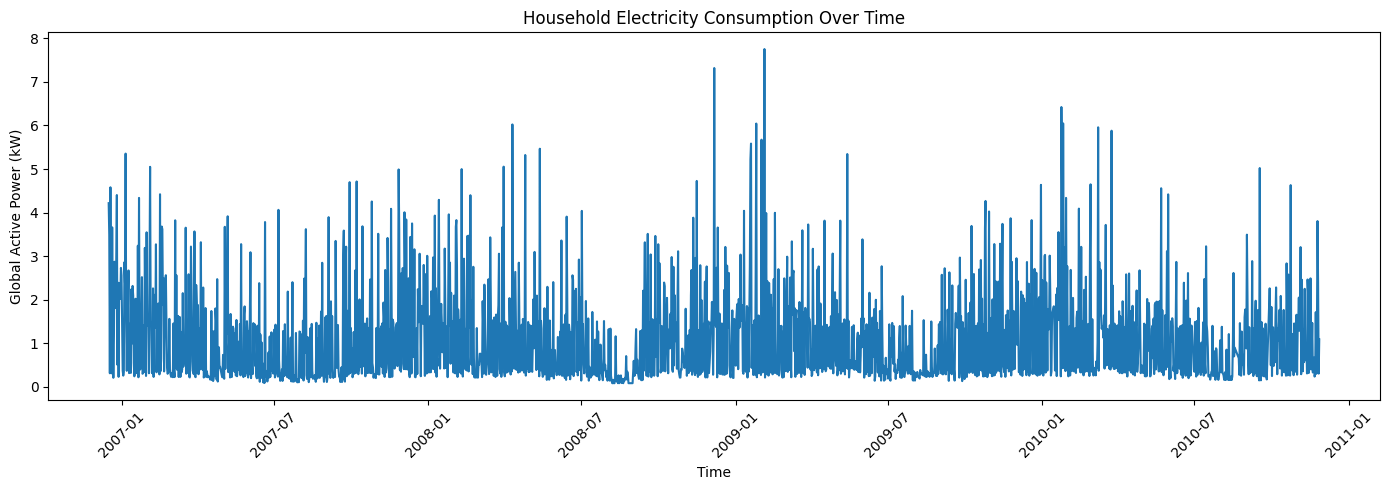

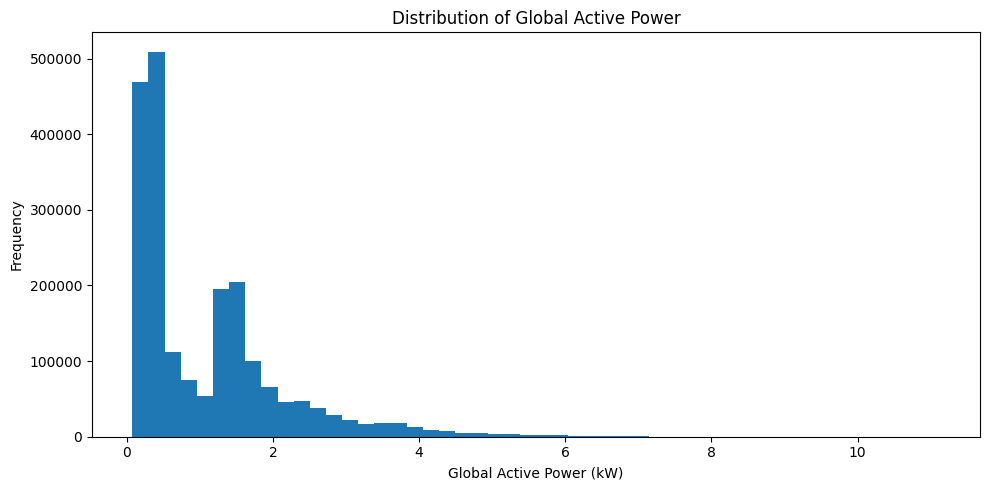

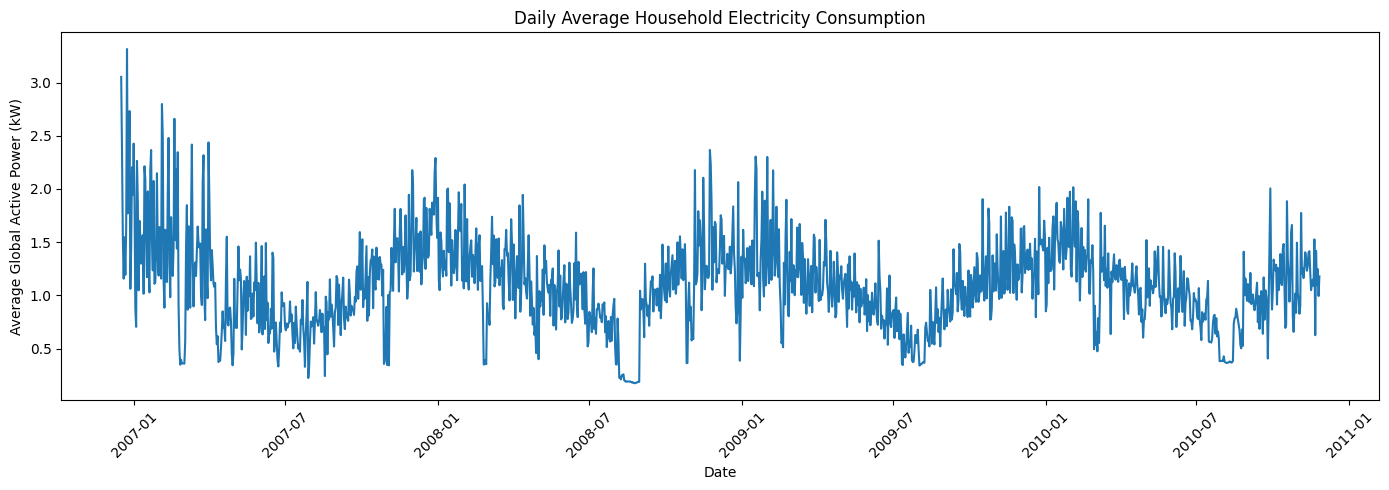

In [ ]:
# ============================================================
# TASK 4 - EDA VISUALIZATIONS
# ============================================================

plot_df = df.iloc[::1000].copy()

plt.figure(figsize=(14, 5))
plt.plot(plot_df["Datetime"], plot_df["Global_active_power"])
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.title("Household Electricity Consumption Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(df["Global_active_power"], bins=50)
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of Global Active Power")
plt.tight_layout()
plt.show()

daily = df.set_index("Datetime")["Global_active_power"].resample("1D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values)
plt.xlabel("Date")
plt.ylabel("Average Global Active Power (kW)")
plt.title("Daily Average Household Electricity Consumption")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


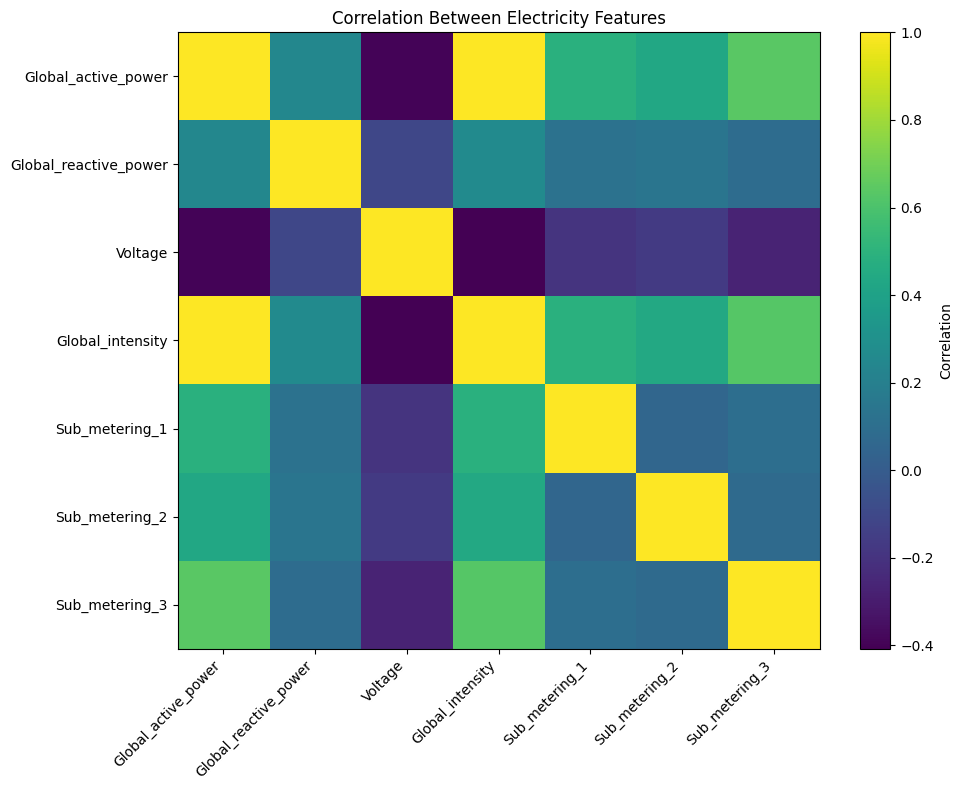

In [ ]:
# ============================================================
# TASK 4 - CORRELATION MATRIX
# ============================================================

correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.title("Correlation Between Electricity Features")
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# TASK 4 - SAVE FINAL CLEANED DATASET
# ============================================================

df_cleaned = df[
    ["Datetime"] + numeric_cols
].copy()

output_path = "/content/household_power_cleaned.csv"
df_cleaned.to_csv(output_path, index=False)

print("Final cleaned dataset shape:", df_cleaned.shape)
print("Missing values:", df_cleaned.isnull().sum().sum())
print("Saved to:", output_path)
display(df_cleaned.head())


Final cleaned dataset shape: (2075259, 8)
Missing values: 0
Saved to: /content/household_power_cleaned.csv


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


# Task 5 — Real-World Feature Engineering

## Important update

The previous version predicted **current** `Global_active_power` using measurements such as
`Global_intensity`, `Voltage`, and sub-meter readings from the same instant.

That is valid as a regression exercise, but it is less useful for a real optimizer because
those measurements are already strongly related to the current power.

This version performs **forecasting**.

### Prediction problem

At time **T**, the model receives only information that is already known:

- previous power readings
- recent rolling-average power
- hour/day/month information

and predicts:

> **Global Active Power at T + 1 hour**

The raw minute-level data is resampled to **15-minute averages**.
Therefore, 1 hour ahead = 4 future 15-minute steps.


In [ ]:
# ============================================================
# TASK 5 - CREATE 15-MINUTE TIME SERIES
# ============================================================

df = pd.read_csv(
    "/content/household_power_cleaned.csv",
    parse_dates=["Datetime"]
)

# Only past Global Active Power is needed for the forecasting model.
power = (
    df[["Datetime", "Global_active_power"]]
    .set_index("Datetime")
    .resample("15min")
    .mean()
)

# Fill rare gaps created during resampling.
power["Global_active_power"] = (
    power["Global_active_power"]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

print("15-minute time-series shape:", power.shape)
display(power.head())


In [ ]:
# ============================================================
# TASK 5 - CREATE REAL-WORLD FORECAST FEATURES
# ============================================================

forecast_df = power.copy()

# -----------------------------
# A. Past consumption features
# -----------------------------
# Each step = 15 minutes.
forecast_df["Lag_15min"] = forecast_df["Global_active_power"].shift(1)
forecast_df["Lag_1hour"] = forecast_df["Global_active_power"].shift(4)
forecast_df["Lag_2hour"] = forecast_df["Global_active_power"].shift(8)
forecast_df["Lag_24hour"] = forecast_df["Global_active_power"].shift(96)
forecast_df["Lag_7day"] = forecast_df["Global_active_power"].shift(96 * 7)

# Rolling means use shift(1), so the current/future target is never leaked.
forecast_df["RollingMean_1hour"] = (
    forecast_df["Global_active_power"].shift(1).rolling(4).mean()
)

forecast_df["RollingMean_4hour"] = (
    forecast_df["Global_active_power"].shift(1).rolling(16).mean()
)

forecast_df["RollingMean_24hour"] = (
    forecast_df["Global_active_power"].shift(1).rolling(96).mean()
)

# -----------------------------
# B. Calendar features
# -----------------------------
forecast_df["Hour"] = forecast_df.index.hour
forecast_df["DayOfWeek"] = forecast_df.index.dayofweek
forecast_df["Month"] = forecast_df.index.month
forecast_df["IsWeekend"] = (forecast_df["DayOfWeek"] >= 5).astype(int)

forecast_df["Hour_sin"] = np.sin(2 * np.pi * forecast_df["Hour"] / 24)
forecast_df["Hour_cos"] = np.cos(2 * np.pi * forecast_df["Hour"] / 24)

forecast_df["DayOfWeek_sin"] = np.sin(
    2 * np.pi * forecast_df["DayOfWeek"] / 7
)
forecast_df["DayOfWeek_cos"] = np.cos(
    2 * np.pi * forecast_df["DayOfWeek"] / 7
)

forecast_df["Month_sin"] = np.sin(
    2 * np.pi * forecast_df["Month"] / 12
)
forecast_df["Month_cos"] = np.cos(
    2 * np.pi * forecast_df["Month"] / 12
)

# -----------------------------
# C. Future target
# -----------------------------
FORECAST_STEPS = 4   # 4 x 15 min = 1 hour

forecast_df["Target_1hour_ahead"] = (
    forecast_df["Global_active_power"].shift(-FORECAST_STEPS)
)

# Remove rows affected by lagging / future shifting.
forecast_df = forecast_df.dropna().copy()

print("Forecasting dataset shape:", forecast_df.shape)
display(forecast_df.head())


In [ ]:
# ============================================================
# TASK 5 - DEFINE X AND y
# ============================================================

feature_columns = [
    "Lag_15min",
    "Lag_1hour",
    "Lag_2hour",
    "Lag_24hour",
    "Lag_7day",
    "RollingMean_1hour",
    "RollingMean_4hour",
    "RollingMean_24hour",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Month_sin",
    "Month_cos"
]

TARGET = "Target_1hour_ahead"

X = forecast_df[feature_columns].copy()
y = forecast_df[TARGET].copy()

print("Input features:")
for col in feature_columns:
    print("✓", col)

print("\nTarget:")
print("✓", TARGET, "(Global Active Power 1 hour in the future)")


In [ ]:
# ============================================================
# TASK 5 - CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

split_index = int(len(X) * 0.80)

X_train_raw = X.iloc[:split_index].copy()
X_test_raw = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

test_timestamps = X_test_raw.index.copy()

print("Training samples:", len(X_train_raw))
print("Testing samples :", len(X_test_raw))

print("\nTraining period:")
print(X_train_raw.index.min(), "to", X_train_raw.index.max())

print("\nTesting period:")
print(X_test_raw.index.min(), "to", X_test_raw.index.max())


In [ ]:
# ============================================================
# TASK 5 - SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

X_train = pd.DataFrame(
    X_train_scaled,
    columns=feature_columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    X_test_scaled,
    columns=feature_columns,
    index=X_test_raw.index
)

print("Scaling completed without using test-set statistics.")


In [ ]:
# ============================================================
# TASK 5 - FEATURE IMPORTANCE
# ============================================================

# Use a manageable training sample for importance analysis.
importance_n = min(50000, len(X_train_raw))

importance_X = X_train_raw.iloc[-importance_n:]
importance_y = y_train.iloc[-importance_n:]

importance_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

importance_model.fit(importance_X, importance_y)

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_table)

importance_table.to_csv(
    "/content/feature_importance_forecasting.csv",
    index=False
)


In [ ]:
# ============================================================
# TASK 5 - SAVE ML-READY DATA
# ============================================================

X_train.to_csv("/content/X_train_forecasting.csv", index=True)
X_test.to_csv("/content/X_test_forecasting.csv", index=True)

y_train.to_csv("/content/y_train_forecasting.csv", index=True)
y_test.to_csv("/content/y_test_forecasting.csv", index=True)

joblib.dump(scaler, "/content/forecast_feature_scaler.joblib")

print("Task 5 outputs saved.")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# Task 6 — Classical Machine Learning Forecasting

The models now predict **future electricity consumption 1 hour ahead**.

Models:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Evaluation:
- MAE
- MSE
- RMSE
- R²

A **naive persistence baseline** is also included. It simply assumes that power one hour from
now will equal the most recently observed power. A useful forecasting model should improve
over this simple baseline.


In [ ]:
# ============================================================
# TASK 6 - TRAIN AND EVALUATE CLASSICAL ML MODELS
# ============================================================

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=80,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=120,
        max_depth=3,
        learning_rate=0.05,
        random_state=42
    )
}

results = []
predictions = {}

# Naive baseline: use latest known 15-minute power as the 1-hour-ahead prediction.
baseline_pred = X_test_raw["Lag_15min"].values

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

results.append({
    "Model": "Naive Persistence Baseline",
    "MAE": baseline_mae,
    "MSE": baseline_mse,
    "RMSE": baseline_rmse,
    "R2": baseline_r2,
    "Training Time (s)": 0.0
})

predictions["Naive Persistence Baseline"] = baseline_pred

for name, model in models.items():
    print("\nTraining:", name)

    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (s)": training_time
    })

    predictions[name] = y_pred

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nMODEL COMPARISON")
display(results_df)


In [ ]:
# ============================================================
# TASK 6 - BEST MODEL + ERROR ANALYSIS
# ============================================================

best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

print("Best model based on lowest test RMSE:", best_model_name)

plot_count = min(500, len(y_test))

plt.figure(figsize=(14, 5))
plt.plot(
    test_timestamps[:plot_count],
    y_test.iloc[:plot_count].values,
    label="Actual 1-hour-ahead power"
)
plt.plot(
    test_timestamps[:plot_count],
    best_predictions[:plot_count],
    label="Predicted 1-hour-ahead power"
)
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.title(f"1-Hour-Ahead Forecast: Actual vs Predicted - {best_model_name}")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

errors = y_test.values - best_predictions

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=50)
plt.xlabel("Forecast Error (kW)")
plt.ylabel("Frequency")
plt.title(f"Forecast Error Distribution - {best_model_name}")
plt.tight_layout()
plt.show()

results_df.to_csv(
    "/content/task6_forecasting_model_comparison.csv",
    index=False
)

prediction_output = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual_1hour_ahead_kW": y_test.values,
    "Predicted_1hour_ahead_kW": best_predictions,
    "Error_kW": errors
})

prediction_output.to_csv(
    "/content/task6_best_forecast_predictions.csv",
    index=False
)

print("Task 6 outputs saved.")


# Optional Separate DL Module — Feed-Forward Neural Network

This is a **separate deep-learning experiment** using the same real-world forecasting features.

It does **not** replace the classical ML comparison. Its purpose is to test whether a neural
network can learn useful nonlinear relationships between past consumption, rolling averages,
and calendar patterns.

**Input:** engineered past/history features  
**Output:** Global Active Power 1 hour ahead


In [ ]:
# ============================================================
# OPTIONAL DL - FEED-FORWARD NEURAL NETWORK
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

dl_model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dropout(0.10),
    Dense(16, activation="relu"),
    Dense(1)
])

dl_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = dl_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=40,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1,
    shuffle=False
)

dl_pred = dl_model.predict(X_test, verbose=0).ravel()

dl_mae = mean_absolute_error(y_test, dl_pred)
dl_mse = mean_squared_error(y_test, dl_pred)
dl_rmse = np.sqrt(dl_mse)
dl_r2 = r2_score(y_test, dl_pred)

print("DL Neural Network")
print("MAE :", dl_mae)
print("MSE :", dl_mse)
print("RMSE:", dl_rmse)
print("R²  :", dl_r2)

dl_model.save("/content/dl_forecasting_model.keras")


# Optional Separate LSTM Module — Sequence Forecasting

LSTM is used differently from the tabular ML/DL models.

Instead of manually giving it lag columns, the LSTM receives a **continuous sequence of past
power readings**.

### LSTM input

The previous **24 hours** of 15-minute power values:

`96 time steps × 1 power feature`

### LSTM output

`Global Active Power 1 hour after the end of that sequence`

This is the most natural time-series forecasting component of the project.


In [ ]:
# ============================================================
# OPTIONAL LSTM - PREPARE SEQUENCES
# ============================================================

from tensorflow.keras.layers import LSTM

series = power["Global_active_power"].values.astype("float32")
timestamps = power.index

SEQUENCE_LENGTH = 96   # 24 hours of 15-minute readings
HORIZON = 4            # predict 1 hour ahead

# Chronological split is done BEFORE fitting the scaler.
raw_split = int(len(series) * 0.80)

series_scaler = StandardScaler()
series_scaler.fit(series[:raw_split].reshape(-1, 1))

series_scaled = series_scaler.transform(
    series.reshape(-1, 1)
).astype("float32")

def make_sequences(values, start_target, end_target, sequence_length, horizon):
    X_seq, y_seq, target_positions = [], [], []

    for target_idx in range(start_target, end_target):
        sequence_end = target_idx - horizon + 1
        sequence_start = sequence_end - sequence_length

        if sequence_start < 0:
            continue

        X_seq.append(values[sequence_start:sequence_end])
        y_seq.append(values[target_idx, 0])
        target_positions.append(target_idx)

    return (
        np.array(X_seq, dtype="float32"),
        np.array(y_seq, dtype="float32"),
        np.array(target_positions)
    )

X_lstm_train, y_lstm_train, train_pos = make_sequences(
    series_scaled,
    start_target=SEQUENCE_LENGTH + HORIZON - 1,
    end_target=raw_split,
    sequence_length=SEQUENCE_LENGTH,
    horizon=HORIZON
)

X_lstm_test, y_lstm_test, test_pos = make_sequences(
    series_scaled,
    start_target=raw_split,
    end_target=len(series_scaled),
    sequence_length=SEQUENCE_LENGTH,
    horizon=HORIZON
)

print("LSTM training shape:", X_lstm_train.shape)
print("LSTM testing shape :", X_lstm_test.shape)
print("Each sample = 96 past 15-minute power readings.")


In [ ]:
# ============================================================
# OPTIONAL LSTM - TRAIN
# ============================================================

tf.random.set_seed(42)

lstm_model = Sequential([
    LSTM(48, input_shape=(SEQUENCE_LENGTH, 1)),
    Dense(24, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    validation_split=0.20,
    epochs=30,
    batch_size=256,
    callbacks=[lstm_early_stop],
    verbose=1,
    shuffle=False
)


In [ ]:
# ============================================================
# OPTIONAL LSTM - EVALUATE IN ORIGINAL kW UNITS
# ============================================================

lstm_pred_scaled = lstm_model.predict(
    X_lstm_test,
    verbose=0
).ravel()

lstm_pred = series_scaler.inverse_transform(
    lstm_pred_scaled.reshape(-1, 1)
).ravel()

lstm_actual = series_scaler.inverse_transform(
    y_lstm_test.reshape(-1, 1)
).ravel()

lstm_mae = mean_absolute_error(lstm_actual, lstm_pred)
lstm_mse = mean_squared_error(lstm_actual, lstm_pred)
lstm_rmse = np.sqrt(lstm_mse)
lstm_r2 = r2_score(lstm_actual, lstm_pred)

print("LSTM 1-hour-ahead forecasting")
print("MAE :", lstm_mae)
print("MSE :", lstm_mse)
print("RMSE:", lstm_rmse)
print("R²  :", lstm_r2)

lstm_model.save("/content/lstm_forecasting_model.keras")
joblib.dump(
    series_scaler,
    "/content/lstm_series_scaler.joblib"
)

lstm_output = pd.DataFrame({
    "Timestamp": timestamps[test_pos],
    "Actual_1hour_ahead_kW": lstm_actual,
    "Predicted_1hour_ahead_kW": lstm_pred
})

lstm_output.to_csv(
    "/content/lstm_forecast_predictions.csv",
    index=False
)

plot_count = min(500, len(lstm_actual))

plt.figure(figsize=(14, 5))
plt.plot(
    timestamps[test_pos[:plot_count]],
    lstm_actual[:plot_count],
    label="Actual"
)
plt.plot(
    timestamps[test_pos[:plot_count]],
    lstm_pred[:plot_count],
    label="LSTM Forecast"
)
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.title("LSTM: Actual vs Predicted Power 1 Hour Ahead")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


# Final Project Interpretation

The updated pipeline has three clearly separated learning components:

| Component | Input | Output | Purpose |
|---|---|---|---|
| Classical ML | Past power + calendar features | Power 1 hour ahead | Compare standard regression algorithms |
| Separate DL | Engineered past/history features | Power 1 hour ahead | Learn nonlinear relationships with a neural network |
| LSTM | Previous 24-hour power sequence | Power 1 hour ahead | Learn temporal/sequential patterns |

The prediction can later be passed to the **rule-based inference layer**.

Example:

`Forecasted high demand + peak tariff + flexible appliance → recommend delaying the appliance`

The rule engine remains responsible for the final explainable action such as
**Keep ON**, **Delay**, or **Turn OFF**.
